# Lab Assignment 1 - Convolutional Neural Networks

Run from the assignment directory, in order, with both smoke flags set to False. The full run uses CIFAR-10, seed 2223 and 20 epochs per configuration. Tasks 2, 3 and 4 create new training directories. Tasks 4 to 6 read those checkpoints and logs, then save the evaluation files under the Task 4 run ID. The last evaluation uses the selected checkpoint on the official test set.


# Part B Assignment

Use this section to develop the main tasks and, optionally, the two challenges. Each task has a broad description followed by one consolidated answer code cell. You may design different interfaces, experiments and plots. Justify your choices and follow the accompanying assignment description for submission requirements.

## Task 1. Study and Prepare the Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from pathlib import Path
# cpu as a fallback
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: mps


In [3]:
from IPython.display import display
from torchvision.datasets.utils import download_and_extract_archive
DATA_ROOT = Path("data")
try:
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)
except:
  # faster than download with datasets
  download_and_extract_archive(
      "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz",
      download_root=str(DATA_ROOT),
      filename="cifar-10-python.tar.gz",
      md5="c58f30108f718f92721af3b95e74349a",
  )
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)

labels = np.asarray(database.targets)
class_names = database.classes

print("Images:", database.data.shape, database.data.dtype)
print("Pixel range:", database.data.min(), database.data.max())
display(
    pd.DataFrame(
        {
            "class": class_names,
            "count": np.bincount(labels, minlength=10),
        }
    )
)

Images: (50000, 32, 32, 3) uint8
Pixel range: 0 255


,class,count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


**Q: What does an example represent, and how are the classes distributed?**

An example is a 32x32 RGB image with a single class label from the ten CIFAR-10 categories. The official training set has 50,000 images with pixel values in [0, 255], and the classes are balanced (5,000 images per class).


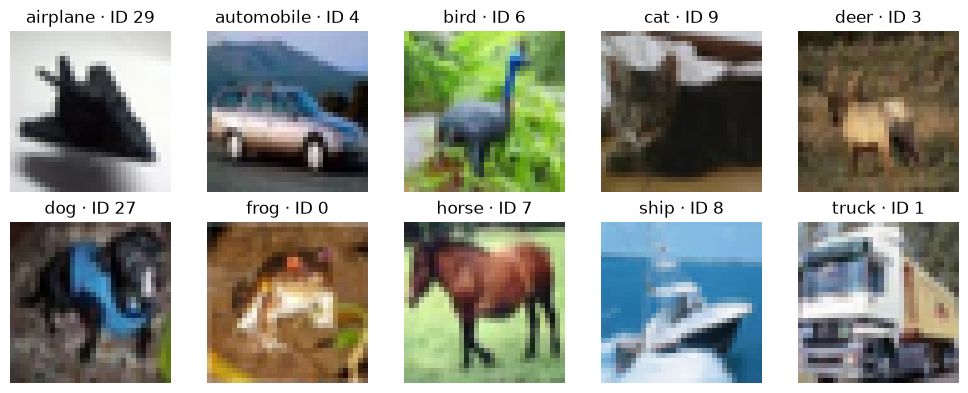

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for target, ax in enumerate(axes.flat):
    image_id = int(np.flatnonzero(labels == target)[0])
    ax.imshow(database.data[image_id])
    ax.set_title(f"{class_names[target]} · ID {image_id}")
    ax.axis("off")
fig.tight_layout()
plt.show()

In [5]:

from sklearn.model_selection import train_test_split
SEED = 2223

train_ids, val_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=SEED,
)
train_ids, val_ids = np.sort(train_ids), np.sort(val_ids)
assert set(train_ids).isdisjoint(val_ids)

print("Training / validation:", len(train_ids), len(val_ids))


Training / validation: 45000 5000


In [6]:
test_database = datasets.CIFAR10(DATA_ROOT, train=False, download=False)
test_ids = np.arange(len(test_database))
print("Test:", len(test_ids))
assert set(train_ids).isdisjoint(val_ids)

Test: 10000


In [7]:
from tqdm import tqdm

channel_sum = np.zeros(3)
channel_square_sum = np.zeros(3)
pixel_count = 0

# we process images in a batch of 256
for start in tqdm(range(0, len(train_ids), 256)):
    pixels = database.data[train_ids[start : start + 256]].astype(np.float64) / 255
    channel_sum += pixels.sum(axis=(0, 1, 2)) # sum across samples in a batch, image heights, image widths
    channel_square_sum += np.square(pixels).sum(axis=(0, 1, 2))
    pixel_count += np.prod(pixels.shape[:3])

mean = channel_sum / pixel_count
std = np.sqrt(np.maximum(channel_square_sum / pixel_count - mean**2, 1e-12))
stats = {"mean": mean.tolist(), "std": std.tolist()}
display(pd.DataFrame(stats, index=["red", "green", "blue"]))

100%|████████████████████████████████████████████████████████████████████| 176/176 [00:00<00:00, 841.70it/s]


,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


In [8]:
class RawImages(Dataset):
    def __init__(self, dataset, ids):
        self.dataset = dataset
        self.ids = list(map(int, ids))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):  # ty: ignore[lost-keyword-for-regular-parameter]
        image_id = self.ids[idx]
        image, target = self.dataset[image_id]
        return TF.to_tensor(image), int(target), image_id

In [9]:
def prepare_inputs(raw, stats):
    mean = raw.new_tensor(stats["mean"])[None, :, None, None]
    std = raw.new_tensor(stats["std"])[None, :, None, None]
    return (raw - mean) / std

**Q: Which preprocessing steps are needed for the two architectures?**

Both AlexNet and ResNet use the CIFAR-10 adaptations from Part A9, so they take native 3x32x32 inputs. We apply the same preprocessing to both: convert uint8 images to float tensors in [0, 1], then normalize each channel with the mean and standard deviation computed on the training split only.


**Q: How is the dataset preprocessed and splitted?**

We split the official training set into 45,000 training and 5,000 validation images (stratified 90/10, seed 2223). The official 10,000-image test set is held out for final evaluation. Images are converted to [0, 1] tensors and normalized with training-set mean/std.

In [10]:
# This class has been created here as it is necessary for the loader for task 4.
# It will be relevant for task 4


class AugmentedImages(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

        # crop adds 4 pixels of padding around the image and then selects a 32x32 cell
        self.transform = transforms.Compose([
            transforms.RandomCrop(
                size=32,
                padding=4,
                padding_mode="reflect",
            ),
            transforms.RandomHorizontalFlip(p=0.5), # horizontal flip applies a mirror of the image left to right with probability p
        ])

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        # apply the transformation
        image, target, image_id = self.base_dataset[index]
        augmented_image = self.transform(image)
        return augmented_image, target, image_id


In [11]:
import random
from dataclasses import asdict, dataclass, replace


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


@dataclass
class Run:
    name: str
    model: str = "AlexNet"
    group: str = "baseline"
    seed: int = 2223
    epochs: int = 20
    batch_size: int = 64
    lr: float = 0.01
    momentum: float = 0.9
    l2: float = 0.0
    dropout: float = 0.5
    width_mult: float = 1.0
    augmentation: bool = False
    smoke: bool = False

    def get_smoke(self, epochs: int = 1) -> "Run":
        return replace(self, smoke=True, epochs=epochs)


@dataclass
class Loaders:
    train: DataLoader
    train_eval: DataLoader
    val: DataLoader
    test: DataLoader | None = None


def make_loaders(
    run: Run,
    train_subset,
    val_subset,
    *,
    include_test=False,
) -> Loaders:

    generator = torch.Generator().manual_seed(run.seed)

    # Clean training images, also used for training-set evaluation.
    clean_train = RawImages(database, train_subset)

    # Apply augmentation only when the run requests it.
    training_data = (
        AugmentedImages(clean_train)
        if run.augmentation
        else clean_train
    )

    def make_loader(dataset, *, shuffle=False):
        return DataLoader(
            dataset,
            batch_size=run.batch_size,
            shuffle=shuffle,
            num_workers=0,
            pin_memory=device.type == "cuda",
            generator=generator if shuffle else None,
        )

    return Loaders(
        train=make_loader(training_data, shuffle=True),
        train_eval=make_loader(clean_train),
        val=make_loader(RawImages(database, val_subset)),
        test=(
            make_loader(RawImages(test_database, test_ids))
            if include_test
            else None
        ),
    )



inspect_run = Run(name="inspect", seed=SEED, batch_size=128, epochs=1)
set_seed(inspect_run.seed)
loaders = make_loaders(inspect_run, train_ids, val_ids, include_test=True)
print(
    f"{inspect_run.name}: "
    f"{len(loaders.train)} train / {len(loaders.val)} val / {len(loaders.test)} test batches"
)


inspect: 352 train / 40 val / 79 test batches


**Q: How to control the randomness in the experiment?**

We fix the train/validation split with `SEED = 2223`, seed Python/NumPy/PyTorch through `set_seed`, and rebuild each DataLoader shuffle generator from `Run.seed`. That keeps the partition and batch order stable across runs.


## Task 2. Implement and Compare the Models
Implement and train AlexNet and ResNet using PyTorch layers, starting from the architectures and CIFAR-10 adaptations discussed in A9. Explain any differences from the original designs, observe feature shapes and compare the models under a justified compute budget. Do not use pretrained weights or readily-available model constructors.

Choose your optimizer, training schedule, checkpoint rule and evaluation metrics. Justify your choices. Report numerical performance, parameter counts, training cost, number of trained samples and relevant limitations. You are free to define different model construction, training and evaluation rather than following part A.

In [12]:
# AlexNet
class AlexNet(nn.Module):
    def __init__(self, dropout: float = 0.5, width_mult: float = 1.0):
        super().__init__()

        def width(channels: int) -> int:
            return max(8, int(round(channels * width_mult)))

        c1, c2, c3, c4, c5 = map(width, (64, 192, 384, 256, 256))
        fc1, fc2 = map(width, (1024, 512))
        flat = c5 * 4 * 4

        self.network = nn.Sequential(
            nn.Conv2d(3, c1, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c1, c2, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c2, c3, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c3, c4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c4, c5, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(flat, fc1),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc1, fc2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc2, 10),
        )

    def forward(self, x):
        return self.network(x)


AlexNet()(torch.randn(2, 3, 32, 32)).shape


torch.Size([2, 10])

In [13]:
# BasicBlock

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=stride,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )

        self.shortcut = self.build_shortcut(in_channels, out_channels, stride)
        self.relu = nn.ReLU()

    def build_shortcut(self, in_channels, out_channels, stride):
        if stride == 1 and in_channels == out_channels:
            return nn.Identity()
        else:
            return nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        return self.relu(self.shortcut(x) + self.network(x))


print(BasicBlock(64, 64, 1)(torch.randn(2, 64, 32, 32)).shape)
print(BasicBlock(64, 128, 2)(torch.randn(2, 64, 32, 32)).shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 128, 16, 16])


In [14]:
# ResNet

class ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Stage 1
            BasicBlock(64, 64, 1),
            BasicBlock(64, 64, 1),

            # Stage 2
            BasicBlock(64, 128, 2),
            BasicBlock(128, 128, 1),

            # Stage 3
            BasicBlock(128, 256, 2),
            BasicBlock(256, 256, 1),

            # Stage 4
            BasicBlock(256, 512, 2),
            BasicBlock(512, 512, 1),
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Linear(
                in_features=512,
                out_features=10
            )
        )

    def forward(self, x):
        return self.network(x)

ResNet()(torch.randn(2, 3, 32, 32)).shape

torch.Size([2, 10])

In [15]:
import json
import time
import uuid
from datetime import datetime, timezone


def build_model(run: Run) -> nn.Module:
    if run.model == "AlexNet":
        return AlexNet(dropout=run.dropout, width_mult=run.width_mult)
    if run.model == "ResNet18":
        return ResNet()
    raise ValueError(f"Unknown model: {run.model}")


for run in (
    Run(name="check_alexnet", model="AlexNet"),
    Run(name="check_resnet", model="ResNet18"),
):
    model = build_model(run)
    print(run.model)
    print(model)
    print("parameters:", sum(p.numel() for p in model.parameters()))
    with torch.no_grad():
        out = model(torch.zeros(2, 3, 32, 32))
    assert out.shape == (2, 10)
    print("output shape:", tuple(out.shape), "\n")
    del model


AlexNet
AlexNet(
  (network): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=4096, out_features=1024, bias=True)
    (15): ReLU()
    (16): Dropout(p=0.5, inplace=False)
    (17): Linear(in_features=1024, out_features=512, bias=True)
    (18): ReL

**Q: Describe and justify the layers, feature-map dimensions, and parameter counts.**

We implement the CIFAR-10 adaptations from Part A9 with plain PyTorch layers (no pretrained weights and no torchvision model constructors).

AlexNet has five 3x3 convolutions with channels 64->192->384->256->256, stride 1 and padding 1, interleaved with three 2x2 max-pools, then a classifier 4096->1024->512->10 with dropout 0.5. After the pools the feature map is 256x4x4, which flattens to 4096 units. This network has about 6.98M parameters. Compared with the original ImageNet AlexNet we use a smaller 3x3 stride-1 stem suited to 32x32 inputs, drop local response normalization, and use a thinner head for ten classes.

ResNet-18 uses a 3x3 stride-1 stem without the original 7x7 convolution or stem max-pool, then four stages of two basic blocks with widths 64->128->256->512 (stride 2 at the start of stages 2-4), global average pooling and a 512->10 linear layer. It has about 11.17M parameters. Convolutions followed by BatchNorm are created with `bias=False`, since BatchNorm already provides a learned shift.


**Q: Describe and justify the input preparation and classification head.**

Both architectures consume the same Task 1 inputs: images are converted to float tensors in [0, 1] and normalized with the mean and standard deviation estimated on the training split only. We keep resolution at 32x32, so no ImageNet-style upsampling is required.

AlexNet's classification head is the fully connected stack 4096->1024->512->10 with dropout 0.5 between the hidden layers. ResNet replaces that wide MLP with global average pooling over the final 512x4x4 map and a single linear layer to 10 logits. In both cases the network returns raw logits and `cross_entropy` applies the log-softmax internally.


**Q: Describe and justify the convolution operations, and the roles they play in the visual task.**

The 3x3 convolutions combine nearby pixels (and later nearby feature responses) into new channel activations, which is how the networks build cues for CIFAR object categories. With padding 1, a stride-1 convolution keeps height and width unchanged, so capacity goes into channels rather than shrinking the map too early. Downsampling is done explicitly: AlexNet uses 2x2 max-pooling, while ResNet uses stride-2 convolutions at the beginning of later stages. That reduction increases the receptive field, so deeper layers integrate information over larger regions of the 32x32 image.


**Q: Describe and justify the optimization and checkpoint-selection procedure.**

We train both models under one shared budget so the comparison is controlled: SGD with learning rate 0.01 and momentum 0.9, cosine decay over 20 epochs, batch size 64, seed 2223, and the same 45,000 / 5,000 train/validation split from Task 1. This baseline uses no data augmentation and no weight decay; AlexNet still uses the dropout from the A9 design. Equal epochs give both models the same number of training examples (900,000 visits including repeats), not equal wall-clock time.

After every epoch we measure validation accuracy and keep the checkpoint with the highest value, breaking ties with lower validation cross-entropy. The official test set is never used to pick a checkpoint.


**Q: Describe and justify the role of residual connections in ResNet.**

Each basic block computes a residual branch `F(x)` and adds it to a shortcut of `x`, then applies ReLU. When channel count and spatial size match, the shortcut is the identity; when the block downsamples or widens, the shortcut is a 1x1 convolution (with BatchNorm) that matches shapes. The skip path lets the block learn a residual correction instead of a full mapping and keeps a direct route for gradients through the stack, which is the main reason this deeper ResNet remains trainable compared with a plain conv stack of similar depth. This experiment still compares full architectures (width, BatchNorm, dropout), so it does not isolate skip connections by themselves.


In [15]:
SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

alexnet_run = Run(
    name="AlexNet",
    model="AlexNet",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
resnet_run = Run(
    name="ResNet18",
    model="ResNet18",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
if SMOKE:
    alexnet_run = alexnet_run.get_smoke()
    resnet_run = resnet_run.get_smoke()
    train_ids = train_ids[:512]
    val_ids = val_ids[:256]

In [16]:
# New folder each time so previous checkpoints are not overwritten.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task2_output_dir = Path("outputs") / "task2" / f"{'smoke' if alexnet_run.smoke else 'full'}_{run_id}"
task2_output_dir.mkdir(parents=True, exist_ok=False)

(task2_output_dir / "config.json").write_text(
    json.dumps(
        {"runs": [asdict(alexnet_run), asdict(resnet_run)], "normalization": stats},
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task2_output_dir / "split_ids.npz", train_ids=train_ids, val_ids=val_ids)
print("Output directory:", task2_output_dir.resolve())


Output directory: E:\ID2223\lab\ID2223-Scalable-Machine-Learning-and-Deep-Learning\assignments\ass1\outputs\task2\full_20261124T203044Z_0e3c820f


In [17]:
@dataclass
class Metrics:
    loss: float
    accuracy: float
    samples: int


@dataclass
class EpochResult:
    epoch: int
    train_loss: float
    train_accuracy: float
    val_loss: float
    val_accuracy: float


@dataclass
class RunSummary:
    name: str
    group: str
    model: str
    smoke: bool
    epochs: int
    dropout: float
    width_mult: float
    l2: float
    parameters: int
    best_epoch: int
    best_val_accuracy: float
    best_val_loss: float
    trained_samples: int
    wall_seconds: float
    checkpoint: str


In [18]:
def train_batch(model, batch, optimizer):
    raw, targets, _ = batch
    raw, targets = raw.to(device), targets.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(prepare_inputs(raw, stats))
    loss = nn.functional.cross_entropy(logits, targets)
    loss.backward()
    optimizer.step()
    count = len(targets)
    correct = (logits.argmax(1) == targets).sum().item()
    return loss.item() * count, correct, count


def train_epoch(model, loader, optimizer, run, epoch) -> Metrics:
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for batch in tqdm(loader, desc=f"[{epoch}/{run.epochs}] {run.name}"):
        batch_loss, batch_correct, batch_count = train_batch(model, batch, optimizer)
        loss_sum += batch_loss
        correct += batch_correct
        count += batch_count
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


@torch.inference_mode()
def evaluate(model, loader, normalization_stats=None) -> Metrics:
    if normalization_stats is None:
        normalization_stats = stats
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for raw, targets, _ in loader:
        raw, targets = raw.to(device), targets.to(device)
        logits = model(prepare_inputs(raw, normalization_stats))
        loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
        correct += (logits.argmax(1) == targets).sum().item()
        count += targets.size(0)
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


def train_model(
    run: Run,
    *,
    output_dir: Path,
    train_ids,
    val_ids,
) -> tuple[list[EpochResult], RunSummary]:
    set_seed(run.seed)
    loaders = make_loaders(run, train_ids, val_ids)
    model = build_model(run).to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=run.lr, momentum=run.momentum, weight_decay=run.l2
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=run.epochs)
    checkpoint_path = output_dir / f"{run.name}_best.pt"

    history: list[EpochResult] = []
    best_key, best_epoch = None, None
    start = time.perf_counter()
    for epoch in range(1, run.epochs + 1):
        training = train_epoch(model, loaders.train, optimizer, run, epoch)
        validation = evaluate(model, loaders.val)
        history.append(
            EpochResult(
                epoch=epoch,
                train_loss=training.loss,
                train_accuracy=training.accuracy,
                val_loss=validation.loss,
                val_accuracy=validation.accuracy,
            )
        )

        key = (validation.accuracy, -validation.loss)
        if best_key is None or key > best_key:
            best_key, best_epoch = key, epoch
            torch.save(
                {
                    "model_name": run.model,
                    "epoch": epoch,
                    "config": asdict(run),
                    "stats": stats,
                    "class_names": class_names,
                    "val_loss": validation.loss,
                    "val_accuracy": validation.accuracy,
                    "state_dict": {
                        k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                    },
                },
                checkpoint_path,
            )

        scheduler.step()
        pd.DataFrame(map(asdict, history)).to_csv(
            output_dir / f"{run.name}_history.csv", index=False
        )

    assert best_key is not None and best_epoch is not None
    summary = RunSummary(
        name=run.name,
        group=run.group,
        model=run.model,
        smoke=run.smoke,
        epochs=run.epochs,
        dropout=run.dropout,
        width_mult=run.width_mult,
        l2=run.l2,
        parameters=sum(p.numel() for p in model.parameters()),
        best_epoch=best_epoch,
        best_val_accuracy=best_key[0],
        best_val_loss=-best_key[1],
        trained_samples=run.epochs * len(train_ids),
        wall_seconds=time.perf_counter() - start,
        checkpoint=str(checkpoint_path),
    )
    del model, optimizer, scheduler
    return history, summary


In [19]:
def evaluate_best_checkpoints(output_dir: Path) -> pd.DataFrame:
    with np.load(output_dir / "split_ids.npz") as split:
        train_ids = split["train_ids"]
        val_ids = split["val_ids"]

    comparison = pd.read_csv(output_dir / "comparison.csv")
    rows = []
    for name in comparison["name"]:
        checkpoint = torch.load(
            output_dir / f"{name}_best.pt", map_location="cpu", weights_only=True
        )
        run = Run(**checkpoint["config"])
        loaders = make_loaders(run, train_ids, val_ids)
        model = build_model(run).to(device)
        model.load_state_dict(checkpoint["state_dict"])

        training = evaluate(model, loaders.train_eval, checkpoint["stats"])
        val_accuracy = checkpoint["val_accuracy"]
        rows.append(
            {
                "name": name,
                "epoch": checkpoint["epoch"],
                "train_samples": training.samples,
                "train_loss": training.loss,
                "train_accuracy": training.accuracy,
                "val_samples": len(val_ids),
                "val_loss": checkpoint["val_loss"],
                "val_accuracy": val_accuracy,
                "accuracy_gap_pp": 100 * (training.accuracy - val_accuracy),
            }
        )

    return pd.DataFrame(rows)



In [20]:
histories, summaries = {}, []
for run in (alexnet_run, resnet_run):
    histories[run.name], summary = train_model(
        run, output_dir=task2_output_dir, train_ids=train_ids, val_ids=val_ids
    )
    summaries.append(summary)
    comparison = pd.DataFrame(map(asdict, summaries))
    comparison.to_csv(task2_output_dir / "comparison.csv", index=False)
display(comparison)
if alexnet_run.smoke:
    print("SMOKE CHECK ONLY: set SMOKE=False and rerun from the configuration cell for report results.")


[1/20] AlexNet:   0%|          | 0/704 [00:00<?, ?it/s]

[1/20] AlexNet:  78%|███████▊  | 549/704 [00:15<00:04, 36.57it/s]

[1/20] AlexNet: 100%|██████████| 704/704 [00:18<00:00, 37.49it/s]

[2/20] AlexNet:   0%|          | 0/704 [00:00<?, ?it/s]

[2/20] AlexNet:  87%|████████▋ | 615/704 [00:15<00:02, 40.96it/s]

[2/20] AlexNet: 100%|██████████| 704/704 [00:17<00:00, 40.90it/s]

... (172 outputs left out)

[20/20] ResNet18:  59%|█████▊    | 412/704 [00:44<00:21, 13.35it/s]

[20/20] ResNet18:  89%|████████▉ | 625/704 [00:45<00:05, 13.72it/s]

[20/20] ResNet18: 100%|██████████| 704/704 [00:51<00:00, 13.73it/s]

,name,group,model,smoke,epochs,dropout,width_mult,l2,parameters,best_epoch,best_val_accuracy,best_val_loss,trained_samples,wall_seconds,checkpoint
0,AlexNet,baseline,AlexNet,False,20,0.5,1.0,0.0,6976842,20,0.8410,0.886199,900000,386.128589,outputs\task2\full_20261124T203044Z_0e3c820f\A...
1,ResNet18,baseline,ResNet18,False,20,0.5,1.0,0.0,11173962,19,0.8508,0.720289,900000,1050.957448,outputs\task2\full_20261124T203044Z_0e3c820f\R...


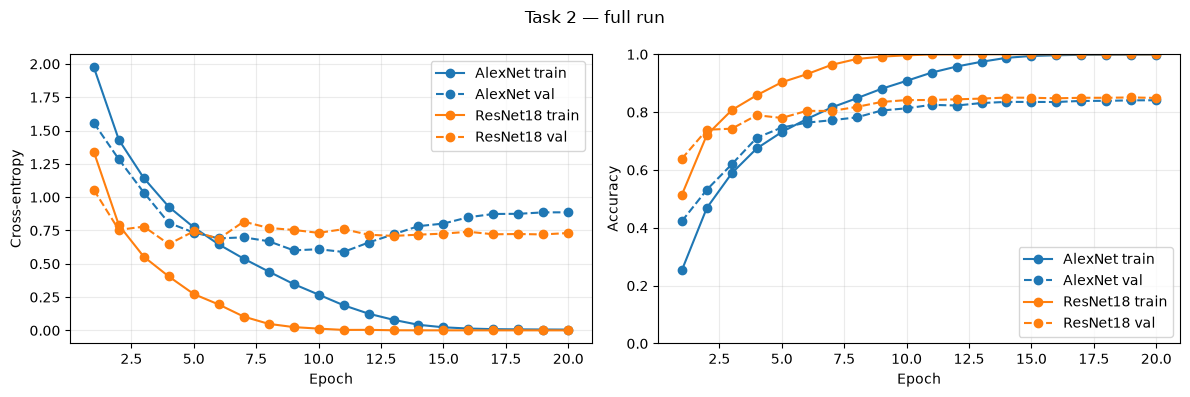

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    epochs = [row.epoch for row in history]
    line, = axes[0].plot(epochs, [row.train_loss for row in history], marker="o", label=f"{name} train")
    color = line.get_color()
    axes[0].plot(epochs, [row.val_loss for row in history], "--o", color=color, label=f"{name} val")
    axes[1].plot(epochs, [row.train_accuracy for row in history], "-o", color=color, label=f"{name} train")
    axes[1].plot(epochs, [row.val_accuracy for row in history], "--o", color=color, label=f"{name} val")
axes[0].set_ylabel("Cross-entropy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle(f"Task 2 — {'smoke' if alexnet_run.smoke else 'full'} run")
fig.tight_layout()
fig.savefig(task2_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


**How did the two baseline models compare?**

| Model | M params | Epoch | Val. acc. | Val. loss | Train acc. | Min |
| --- | --- | --- | --- | --- | --- | --- |
| AlexNet | 6.98 | 20 | 84.10% | 0.886 | 99.92% | 6.44 |
| ResNet18 | 11.17 | 19 | 85.08% | 0.720 | 100.00% | 17.52 |

ResNet-18 reached 85.08% validation accuracy, compared with 84.10% for AlexNet. It took 2.72 times as long. Each model saw 900,000 training examples in 20 epochs. Training accuracy in the table comes from the training log at the selected epoch.

## Task 3. Investigate Capacity and Regularization
Investigate how model capacity (n_channels/width, depth, etc.) and regularization influence learning and generalization. Select a feasible set of comparisons and justify what you change and hold fixed. Include L2 regularization, a condition without dropout and two dropout probabilities of your choice. Use learning curves and deterministic training/validation evaluation to distinguish underfitting, overfitting and incomplete optimization.

You may choose either architecture, modify different stages, or use another controlled experimental design.

In [22]:
TASK3_SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

baseline = Run(
    name="alexnet_baseline",
    model="AlexNet",
    group="shared",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    dropout=0.5,
    width_mult=1.0,
    augmentation=False,
)

task3_runs: list[Run] = [
    baseline,
    replace(baseline, name="alexnet_w0.5", group="capacity", width_mult=0.5),
    replace(baseline, name="alexnet_w1.5", group="capacity", width_mult=1.5),
    replace(baseline, name="alexnet_l2_1e-4", group="l2", l2=1e-4),
    replace(baseline, name="alexnet_l2_1e-3", group="l2", l2=1e-3),
    replace(baseline, name="alexnet_dropout_0.0", group="dropout", dropout=0.0),
    replace(baseline, name="alexnet_dropout_0.25", group="dropout", dropout=0.25),
]

task3_group_members: dict[str, list[str]] = {
    "capacity": ["alexnet_w0.5", "alexnet_baseline", "alexnet_w1.5"],
    "l2": ["alexnet_baseline", "alexnet_l2_1e-4", "alexnet_l2_1e-3"],
    "dropout": ["alexnet_dropout_0.0", "alexnet_dropout_0.25", "alexnet_baseline"],
}

if TASK3_SMOKE:
    task3_runs = [run.get_smoke() for run in task3_runs]
    task3_train_ids = train_ids[:512]
    task3_val_ids = val_ids[:256]
else:
    task3_train_ids = train_ids
    task3_val_ids = val_ids

print("Task 3 runs:")
for run in task3_runs:
    print(asdict(run))


Task 3 runs:
{'name': 'alexnet_baseline', 'model': 'AlexNet', 'group': 'shared', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 1.0, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_w0.5', 'model': 'AlexNet', 'group': 'capacity', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 0.5, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_w1.5', 'model': 'AlexNet', 'group': 'capacity', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 1.5, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_l2_1e-4', 'model': 'AlexNet', 'group': 'l2', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0001, 'dropout': 0.5, 'width_mult': 1.0, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_l2_1e-3', 'model': 'AlexNet', 'group': 'l2', 'seed': 2223, 'epo

In [23]:
task3_run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task3_output_dir = Path("outputs") / "task3" / f"{'smoke' if TASK3_SMOKE else 'full'}_{task3_run_id}"
task3_output_dir.mkdir(parents=True, exist_ok=False)

(task3_output_dir / "config.json").write_text(
    json.dumps(
        {
            "runs": [asdict(run) for run in task3_runs],
            "group_members": task3_group_members,
            "normalization": stats,
            "train_size": len(task3_train_ids),
            "validation_size": len(task3_val_ids),
        },
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task3_output_dir / "split_ids.npz", train_ids=task3_train_ids, val_ids=task3_val_ids)
print("Output directory:", task3_output_dir.resolve())


Output directory: E:\ID2223\lab\ID2223-Scalable-Machine-Learning-and-Deep-Learning\assignments\ass1\outputs\task3\full_20261124T205443Z_0f97d770


In [24]:
task3_histories: dict[str, list[EpochResult]] = {}
task3_summaries: list[RunSummary] = []
for run in task3_runs:
    task3_histories[run.name], summary = train_model(
        run,
        output_dir=task3_output_dir,
        train_ids=task3_train_ids,
        val_ids=task3_val_ids,
    )
    task3_summaries.append(summary)
    comparison_task3 = pd.DataFrame(map(asdict, task3_summaries))
    comparison_task3.to_csv(task3_output_dir / "comparison.csv", index=False)
display(comparison_task3)
if TASK3_SMOKE:
    print("SMOKE CHECK ONLY: set TASK3_SMOKE=False and rerun from the configuration cell for report results.")


[1/20] alexnet_baseline:   0%|          | 0/704 [00:00<?, ?it/s]

[1/20] alexnet_baseline:  80%|████████  | 564/704 [00:15<00:03, 37.57it/s]

[1/20] alexnet_baseline: 100%|██████████| 704/704 [00:18<00:00, 37.51it/s]

[2/20] alexnet_baseline:   0%|          | 0/704 [00:00<?, ?it/s]

[2/20] alexnet_baseline:  73%|███████▎  | 512/704 [00:15<00:05, 34.08it/s]

[2/20] alexnet_baseline: 100%|██████████| 704/704 [00:20<00:00, 34.77it/s]

... (414 outputs left out)

[20/20] alexnet_dropout_0.25:   0%|          | 0/704 [00:00<?, ?it/s]

[20/20] alexnet_dropout_0.25:  85%|████████▌ | 600/704 [00:15<00:02, 39.94it/s]

[20/20] alexnet_dropout_0.25: 100%|██████████| 704/704 [00:17<00:00, 39.93it/s]

,name,group,model,smoke,epochs,dropout,width_mult,l2,parameters,best_epoch,best_val_accuracy,best_val_loss,trained_samples,wall_seconds,checkpoint
0,alexnet_baseline,shared,AlexNet,False,20,0.50,1.0,0.0000,6976842,20,0.8410,0.886199,900000,400.807820,outputs\task3\full_20261124T205443Z_0f97d770\a...
1,alexnet_w0.5,capacity,AlexNet,False,20,0.50,0.5,0.0000,1746602,16,0.8182,0.796997,900000,243.582594,outputs\task3\full_20261124T205443Z_0f97d770\a...
2,alexnet_w1.5,capacity,AlexNet,False,20,0.50,1.5,0.0000,15690730,20,0.8482,0.900491,900000,635.189984,outputs\task3\full_20261124T205443Z_0f97d770\a...
3,alexnet_l2_1e-4,l2,AlexNet,False,20,0.50,1.0,0.0001,6976842,18,0.8372,0.831492,900000,396.041866,outputs\task3\full_20261124T205443Z_0f97d770\a...
4,alexnet_l2_1e-3,l2,AlexNet,False,20,0.50,1.0,0.0010,6976842,18,0.8430,0.577271,900000,380.626081,outputs\task3\full_20261124T205443Z_0f97d770\a...
5,alexnet_dropout_0.0,dropout,AlexNet,False,20,0.00,1.0,0.0000,6976842,19,0.8250,1.266005,900000,372.539798,outputs\task3\full_20261124T205443Z_0f97d770\a...
6,alexnet_dropout_0.25,dropout,AlexNet,False,20,0.25,1.0,0.0000,6976842,19,0.8432,0.967922,900000,373.328665,outputs\task3\full_20261124T205443Z_0f97d770\a...


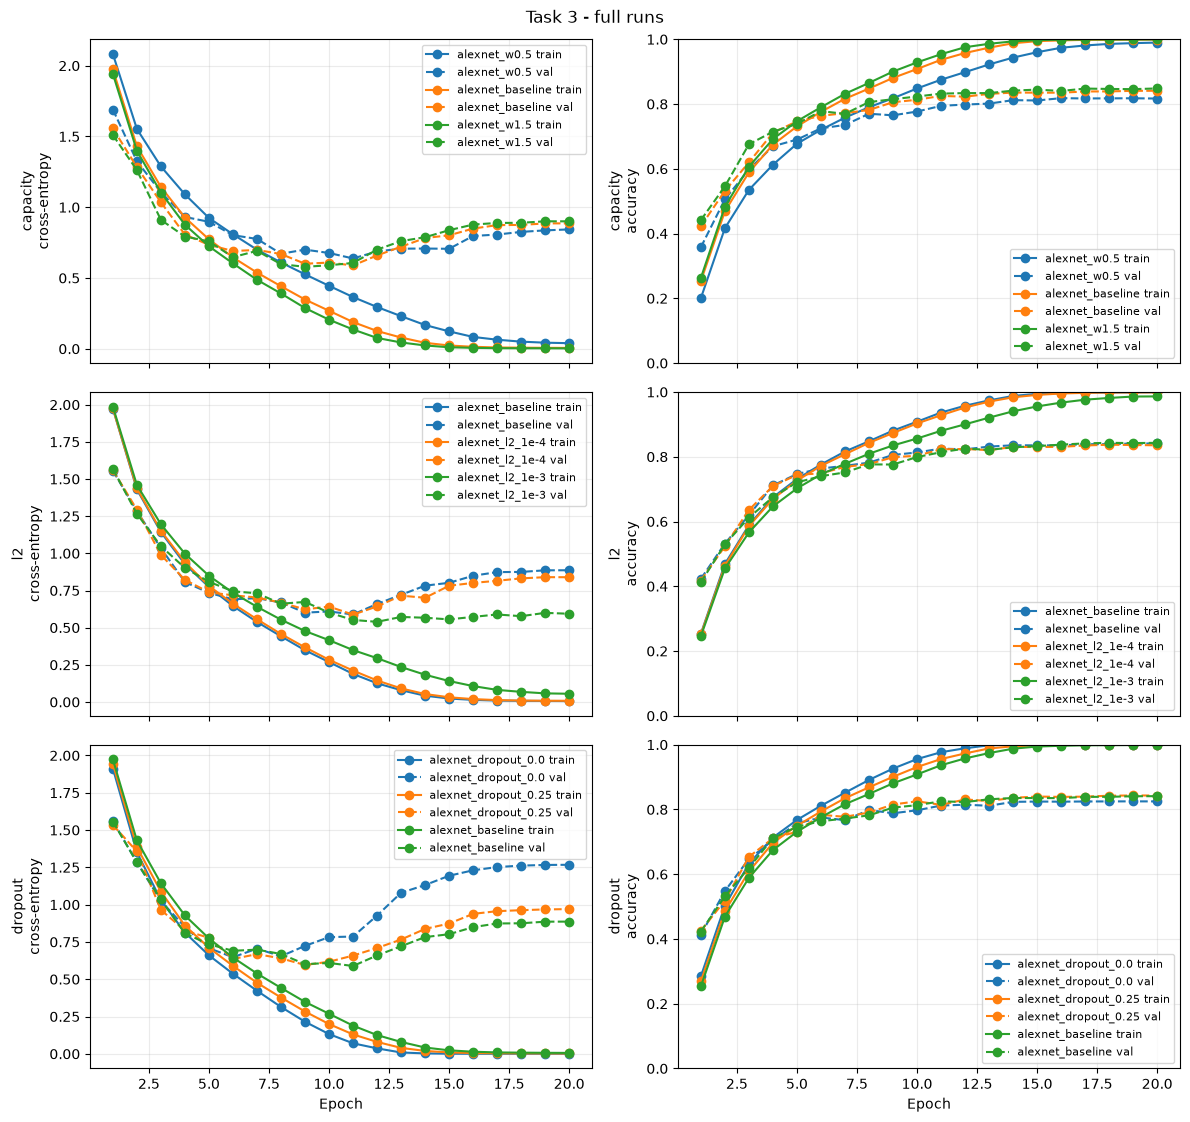

In [25]:
groups = ["capacity", "l2", "dropout"]
fig, axes = plt.subplots(len(groups), 2, figsize=(12, 3.8 * len(groups)), sharex=True)

for row, group in enumerate(groups):
    for name in task3_group_members[group]:
        history = task3_histories[name]
        epochs = [point.epoch for point in history]
        line, = axes[row, 0].plot(
            epochs, [point.train_loss for point in history], marker="o", label=f"{name} train"
        )
        color = line.get_color()
        axes[row, 0].plot(
            epochs, [point.val_loss for point in history], "--o", color=color, label=f"{name} val"
        )
        axes[row, 1].plot(
            epochs, [point.train_accuracy for point in history], "-o", color=color, label=f"{name} train"
        )
        axes[row, 1].plot(
            epochs, [point.val_accuracy for point in history], "--o", color=color, label=f"{name} val"
        )
    axes[row, 0].set_ylabel(f"{group}\ncross-entropy")
    axes[row, 1].set_ylabel(f"{group}\naccuracy")
    axes[row, 1].set_ylim(0, 1)
    for ax in axes[row]:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

axes[-1, 0].set_xlabel("Epoch")
axes[-1, 1].set_xlabel("Epoch")
fig.suptitle(f"Task 3 - {'smoke' if TASK3_SMOKE else 'full'} runs")
fig.tight_layout()
fig.savefig(task3_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


In [26]:
task3_checkpoint_metrics = evaluate_best_checkpoints(task3_output_dir)
display(task3_checkpoint_metrics.round(6))


,name,epoch,train_samples,train_loss,train_accuracy,val_samples,val_loss,val_accuracy,accuracy_gap_pp
0,alexnet_baseline,20,45000,0.001872,0.999844,5000,0.886199,0.8410,15.884444
1,alexnet_w0.5,16,45000,0.042706,0.989333,5000,0.796997,0.8182,17.113333
2,alexnet_w1.5,20,45000,0.000750,0.999956,5000,0.900491,0.8482,15.175556
3,alexnet_l2_1e-4,18,45000,0.003081,0.999711,5000,0.831492,0.8372,16.251111
4,alexnet_l2_1e-3,18,45000,0.041959,0.991444,5000,0.577271,0.8430,14.844444
5,alexnet_dropout_0.0,19,45000,0.000367,1.000000,5000,1.266005,0.8250,17.500000
6,alexnet_dropout_0.25,19,45000,0.000731,0.999978,5000,0.967922,0.8432,15.677778


**Capacity and regularization**

Each run changed one setting of the same baseline (width 1.0, dropout 0.5 and zero weight decay). All seven used the same data, seed, optimizer and 20 epochs.

Train acc. comes from the training log at the selected epoch. Dropout is active during training for runs with a nonzero dropout rate.

| Model | M params | Epoch | Val. acc. | Val. loss | Train acc. | Min |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | 6.98 | 20 | 84.10% | 0.886 | 99.92% | 6.68 |
| w0.5 | 1.75 | 16 | 81.82% | 0.797 | 97.38% | 4.06 |
| w1.5 | 15.69 | 20 | 84.82% | 0.900 | 99.96% | 10.59 |
| l2 1e-4 | 6.98 | 18 | 83.72% | 0.831 | 99.86% | 6.60 |
| l2 1e-3 | 6.98 | 18 | 84.30% | 0.577 | 98.16% | 6.34 |
| dropout 0.0 | 6.98 | 19 | 82.50% | 1.266 | 100.00% | 6.21 |
| dropout 0.25 | 6.98 | 19 | 84.32% | 0.968 | 99.98% | 6.22 |

At half width, training took 4.06 minutes and validation accuracy fell to 81.82%. At 1.5 times the baseline width, accuracy rose by 0.72 points for about four extra minutes. At their selected checkpoints, all seven models classified at least 98.93% of the clean training images correctly. Their training accuracy exceeded validation accuracy by 14.84 to 17.50 points. Even the narrow model fit the training data well.

The baseline validation loss was lowest at epoch 11 and rose as training loss continued to fall. At the selected checkpoints, weight decay of 0.0001 lowered validation loss from 0.886 to 0.831 but also lowered accuracy from 84.10% to 83.72%. Weight decay of 0.001 gave the lowest validation loss (0.577). At epoch 20, this model reached 98.6% training accuracy and 0.594 validation loss. At the same epoch, the model without dropout reached 100% training accuracy and 1.267 validation loss.

Dropout of 0.25 classified 11 more validation images correctly than dropout of 0.5, out of 5,000. We used one seed, so this small lead needs another run to establish whether it holds across seeds. The L2 and dropout comparisons took 6.21 to 6.68 minutes including the baseline. For context, the two baseline runs with the same settings took 6.44 and 6.68 minutes.


## Task 4. Evaluate Robustness
Investigate whether training augmentation improves performance on clean and corrupted images. Choose suitable transformations and parameters, explain how they relate to image changes, and compare models on the same evaluation images. Separate random training views from reproducible evaluation corruptions. Discuss label ambiguity, changed error patterns and cost.

You may start with crop/flip or other corruptions. Develop the method on validation data, and freeze it for final testing.

In [27]:
# Regarding the original model (trained on clean images) we will reuse the checkpoints of previous tasks
checkpoint = torch.load(
    task2_output_dir / "AlexNet_best.pt",
    map_location="cpu",
    weights_only=True,
)

original_run = Run(**checkpoint["config"])

print("Validation accuracy:", f"{checkpoint['val_accuracy']:.2%}")

Validation accuracy: 84.10%


In [28]:
# Reuse the same training hyperparameters as before

augmented_run = replace(
    original_run,
    name="AlexNet_augmented",
    group="robustness",
    augmentation=True,
)

## Why we chose crop and flip

First of all we decided to use the AlexNet because it was the one that showed more overfitting in previous steps of this lab.
This motivates trying to understand whether training augmentation might improve generalization and robustness. 
We compare its existing baseline checkpoint with an AlexNet trained from scratch under the same settings, adding random cropping and horizontal flipping.

We decided to apply two transformations to the training images:

- **Random crop with four pixels of reflection padding:** the image is
  padded and a random crop of 32x32 pixels is selected. 
  This introduces small changes the object position within the image, forcing the model to recognize
  objects without relying on their location in the image.

- **Random horizontal flip with probability 0.5:** the image is mirrored
  left-to-right. CIFAR-10 categories remain unchanged when an
  element faces the opposite direction, so this helps the model to learn to 
  recognize both orientations.

These transformations are applied randomly during training, before
normalization. Validation images remain unchanged. 
Robustness is then measured separately using fixed, reproducible evaluation corruptions shared by both models.

The transformations are deliberately moderate because we thought aggressive cropping might remove important
parts of the elements inside the image and make the label ambiguous.

AugmentedImages as a class is defined before the shared DataLoader for readability.

The training loader applies the crop and flip defined in Task 1.

In [29]:
## Now it's time to train the model under data augmentation

# Create a separate folder for this experiment.
run_id = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:8]
)

task4_output_dir = Path("outputs") / "task4" / run_id
task4_output_dir.mkdir(parents=True, exist_ok=False)

# maintain the hyperparameters settings and data split.
(task4_output_dir / "config.json").write_text(
    json.dumps(
        {
            "run": asdict(augmented_run),
            "normalization": stats,
        },
        indent=2,
    ),
    encoding="utf-8",
)

np.savez(
    task4_output_dir / "split_ids.npz",
    train_ids=train_ids,
    val_ids=val_ids,
)

# train a new AlexNet with random crops and horizontal flips.
augmented_history, augmented_summary = train_model(
    augmented_run,
    output_dir=task4_output_dir,
    train_ids=train_ids,
    val_ids=val_ids,
)

# save the run and the cost
pd.DataFrame([asdict(augmented_summary)]).to_csv(
    task4_output_dir / "training_comparison.csv",
    index=False,
)

print("Checkpoint:", augmented_summary.checkpoint)
print("Best epoch:", augmented_summary.best_epoch)
print(
    "Best clean validation accuracy:",
    f"{augmented_summary.best_val_accuracy:.2%}",
)
print(
    "Training-run time:",
    f"{augmented_summary.wall_seconds / 60:.2f} minutes",
)

[1/20] AlexNet_augmented:   0%|          | 0/704 [00:00<?, ?it/s]

[1/20] AlexNet_augmented:  63%|██████▎   | 442/704 [00:15<00:08, 29.45it/s]

[1/20] AlexNet_augmented: 100%|██████████| 704/704 [00:23<00:00, 29.56it/s]

[2/20] AlexNet_augmented:   0%|          | 0/704 [00:00<?, ?it/s]

[2/20] AlexNet_augmented:  63%|██████▎   | 445/704 [00:15<00:08, 29.65it/s]

[2/20] AlexNet_augmented: 100%|██████████| 704/704 [00:23<00:00, 29.68it/s]

... (51 outputs left out)

[20/20] AlexNet_augmented:   0%|          | 0/704 [00:00<?, ?it/s]

[20/20] AlexNet_augmented:  64%|██████▍   | 452/704 [00:15<00:08, 30.08it/s]

[20/20] AlexNet_augmented: 100%|██████████| 704/704 [00:23<00:00, 30.16it/s]

Checkpoint: outputs\task4\20261124T214229Z_5c04b362\AlexNet_augmented_best.pt
Best epoch: 20
Best clean validation accuracy: 87.36%
Training-run time: 8.23 minutes


Now we would like to evaluate the ability of the two different models to handle different kind of images (clean or augmented).
Let's first define a class which defines the fixed changes (corruptions) that we will apply to the evaluation images in the different cases 
we will cover

In [30]:
from torchvision.transforms import InterpolationMode


class FixedCorruption:
    def __init__(self, kind="clean", severity=0.0, seed=2223):
        self.kind = kind
        self.severity = severity
        self.seed = seed

    def __call__(self, image, image_id):
        if self.kind == "clean":
            return image

        if self.kind == "noise":
            generator = torch.Generator().manual_seed(
                self.seed + int(image_id)
            )

            noise = torch.randn(
                image.shape,
                generator=generator,
                dtype=image.dtype,
            )

            return (image + self.severity * noise).clamp(0, 1)

        if self.kind == "rotation":
            return TF.rotate(
                image,
                angle=self.severity,
                interpolation=InterpolationMode.BILINEAR,
                expand=False,
                fill=0,
            )

        if self.kind == "blur":
            return TF.gaussian_blur(
                image,
                kernel_size=[5, 5],
                sigma=[self.severity, self.severity],
            )

        raise ValueError(f"Unknown corruption: {self.kind}")


conditions = {
    "clean": FixedCorruption(),
    "noise_0.05": FixedCorruption("noise", 0.05),
    "noise_0.10": FixedCorruption("noise", 0.10),
    "rotation_10": FixedCorruption("rotation", 10),
    "rotation_25": FixedCorruption("rotation", 25),
    "blur_0.5": FixedCorruption("blur", 0.5),
    "blur_1.0": FixedCorruption("blur", 1.0),
}


### Modification to the images we applied

To investigate the abilities of the model, we evaluate the original and augmented AlexNet
on the same validation images under the following list of conditions. 
Each "corruption" is applied separately to the original image, before
normalization. The original class label is retained.

| Condition | Transformation | Purpose |
|---|---|---|
| Clean | No modification | Establish reference performance |
| Noise, σ = 0.05 | Add Gaussian noise with standard deviation 0.05 | Test sensitivity to moderate pixel-level disturbances |
| Noise, σ = 0.10 | Add Gaussian noise with standard deviation 0.10 | Test sensitivity to stronger pixel-level disturbances |
| Rotation, 10° | Rotate counterclockwise by 10 degrees | Test sensitivity to a small change in orientation |
| Rotation, 25° | Rotate counterclockwise by 25 degrees | Test sensitivity to a larger change in orientation |
| Blur, σ = 0.5 | Apply Gaussian blur with standard deviation 0.5 pixels | Test sensitivity to mild loss of fine detail |
| Blur, σ = 1.0 | Apply Gaussian blur with standard deviation 1.0 pixels | Test sensitivity to stronger loss of fine detail |

#### Gaussian noise

Noise is added to image tensors whose pixel values are in the interval [0, 1].
The perturbed values are limited to this range. A larger standard
deviation produces stronger disturbances.

For reproducibility, each image receives a noise pattern generated from
a fixed seed. Both models therefore
receive exactly the same noisy images. 

#### Rotation

Images are rotated using bilinear interpolation while keeping their dimensions. Areas outside the original image are filled with
black, and content near the edges may be cropped. Performance changes reflect orientation changes and boundary effects.

#### Gaussian blur

A 5×5 Gaussian filter smooths the image, reducing sharp edges and fine
texture. A larger standard deviation produces stronger smoothing.

#### Fair comparison and label ambiguity

The validation image IDs and corruption settings are identical for both
models. These fixed evaluation modifications are separate from the random
crops and horizontal flips used during augmented training.

The transformations are intended to preserve the class, but stronger
corruptions can make labels ambiguous. Heavy noise or blur may hide
distinguishing features, while rotation may crop important object parts.

### Validation

Now it's time to the test the model under the different abovementioned conditions.
Let's first restore the model's checkpoints


In [31]:
evaluation_models = {}

checkpoints = {
    "Original": checkpoint,
    "Augmented": torch.load(
        task4_output_dir / "AlexNet_augmented_best.pt",
        map_location="cpu",
        weights_only=True,
    ),
}

for name, saved in checkpoints.items():
    model = build_model(Run(**saved["config"]))
    model.load_state_dict(saved["state_dict"])
    model = model.to(device).eval()

    evaluation_models[name] = {
        "model": model,
        "stats": saved["stats"],
    }

task4_eval_dir = Path("results/task4") / task4_output_dir.name
task4_eval_dir.mkdir(parents=True, exist_ok=True)

Let's define now a class with the different evaluation functions


In [32]:
# helper for synhronization
def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


@torch.inference_mode()
def evaluate_corruption(model, normalization_stats, corruption):
    model.eval()
    rows = []

    # no shuffling -> both models receive the same validation images in the same order
    loader = DataLoader(
        RawImages(database, val_ids),
        batch_size=original_run.batch_size,
        shuffle=False,
        num_workers=0,
    )

    for raw, targets, image_ids in loader:
        # apply modifications before normalization.
        changed = torch.stack([
            corruption(image, int(image_id))
            for image, image_id in zip(raw, image_ids)
        ])

        inputs = prepare_inputs(
            changed.to(device),
            normalization_stats,
        )
        logits = model(inputs)

        losses = nn.functional.cross_entropy(
            logits,
            targets.to(device),
            reduction="none",
        )
        predictions = logits.argmax(dim=1).cpu()

        rows.append(pd.DataFrame({
            "image_id": image_ids.numpy(),
            "target": targets.numpy(),
            "prediction": predictions.numpy(),
            "correct": predictions.eq(targets).numpy(),
            "loss": losses.cpu().numpy(),
        }))

    return pd.concat(rows, ignore_index=True)

Now let's run the comparison

In [33]:
prediction_frames = []
evaluation_cost_rows = []

for model_name, saved_model in evaluation_models.items():
    model = saved_model["model"]
    normalization_stats = saved_model["stats"]

    # Warm up before measuring evaluation time.
    with torch.inference_mode():
        dummy = torch.zeros(
            original_run.batch_size, 3, 32, 32,
            device=device,
        )
        for _ in range(3):
            model(prepare_inputs(dummy, normalization_stats))

    synchronize_device()

    for condition_name, corruption in conditions.items():
        synchronize_device()
        start = time.perf_counter()

        predictions = evaluate_corruption(
            model,
            normalization_stats,
            corruption,
        )

        synchronize_device()
        elapsed = time.perf_counter() - start

        predictions["model"] = model_name
        predictions["condition"] = condition_name
        prediction_frames.append(predictions)

        evaluation_cost_rows.append({
            "model": model_name,
            "condition": condition_name,
            "evaluation_seconds": elapsed,
        })

        print(
            f"{model_name:10s} | {condition_name:12s} | "
            f"accuracy: {predictions['correct'].mean():.2%} | "
            f"time: {elapsed:.2f}s"
        )

task4_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)
evaluation_costs = pd.DataFrame(evaluation_cost_rows)

Original   | clean        | accuracy: 84.10% | time: 0.96s


Original   | noise_0.05   | accuracy: 78.32% | time: 1.14s


Original   | noise_0.10   | accuracy: 56.22% | time: 1.14s


Original   | rotation_10  | accuracy: 66.54% | time: 2.10s


Original   | rotation_25  | accuracy: 44.06% | time: 2.22s


Original   | blur_0.5     | accuracy: 80.72% | time: 2.63s


... (4 outputs left out)

Augmented  | rotation_10  | accuracy: 73.50% | time: 2.07s


Augmented  | rotation_25  | accuracy: 51.22% | time: 2.20s


Augmented  | blur_0.5     | accuracy: 84.04% | time: 2.58s


Augmented  | blur_1.0     | accuracy: 51.02% | time: 2.70s


Now let's print a table with the obtained results for a further discussion

In [34]:
robustness = (
    task4_predictions
    .groupby(["model", "condition"], as_index=False)
    .agg(
        accuracy=("correct", "mean"),
        loss=("loss", "mean"),
        samples=("correct", "size"),
    )
    .merge(
        evaluation_costs,
        on=["model", "condition"],
        validate="one_to_one",
    )
)

clean_accuracy = (
    robustness.query("condition == 'clean'")
    .set_index("model")["accuracy"]
)

robustness["drop_pp"] = 100 * (
    robustness["model"].map(clean_accuracy) - robustness["accuracy"]
)

accuracy_table = (
    robustness.pivot(
        index="condition", columns="model", values="accuracy"
    )
    .reindex(conditions)
    .mul(100)
)

accuracy_table["augmentation_gain_pp"] = (
    accuracy_table["Augmented"] - accuracy_table["Original"]
)

for filename, table in {
    "validation_predictions": task4_predictions,
    "validation_robustness": robustness,
}.items():
    table.to_csv(task4_eval_dir / f"{filename}.csv", index=False)

(task4_eval_dir / "corruptions.json").write_text(
    json.dumps(
        {name: vars(corruption) for name, corruption in conditions.items()},
        indent=2,
    ),
    encoding="utf-8",
)

display(accuracy_table.round(2))

model,Augmented,Original,augmentation_gain_pp
condition,,,
clean,87.36,84.10,3.26
noise_0.05,76.74,78.32,-1.58
noise_0.10,44.24,56.22,-11.98
rotation_10,73.50,66.54,6.96
rotation_25,51.22,44.06,7.16
blur_0.5,84.04,80.72,3.32
blur_1.0,51.02,53.86,-2.84


**What changed with augmentation?**

Crop-and-flip training changed clean accuracy by +3.26 percentage points. At 25 degrees of rotation the change was +7.16 points, and at noise level 0.10 it was -11.98 points. The effect depends on the corruption.

For strong noise, Augmented most often predicted frog on its errors (2,022 of 2,788) and Original most often predicted frog on its errors (1,258 of 2,189). Under rotation and strong blur, cat was the most common wrong prediction for both models. Original predicted cat on 1,211 of its 2,797 errors at 25 degrees and on 1,193 of its 2,307 errors under strong blur. Crop and flip leave pixel noise out of training, which may help explain the weaker results under strong noise. Rotation can cut an object off at the border, while blur and noise can hide details needed to identify the class.

Original trained in 6.44 minutes and Augmented in 8.23 minutes on the same GPU. The difference was +27.84% in this run.

## Task 5. Analyse Predictions and Adversarial Examples
Combine quantitative evaluation with examples of successful and unsuccessful predictions. Decide which metrics, visualizations and examples best explain the models' behaviour. Generate an adversarial input against a trained model, describe the perturbation, and assess the observed effect. Distinguish deliberately optimized perturbations from random corruption. Define success for the adversarial attacks. Explain class-specific errors, learning curves and representative images alongside the numerical results.

We follow classroom A7 and A8 for prediction examples, training diagnostics and FGSM. Run the notebook in order from the assignment directory. Original uses the Task 2 AlexNet checkpoint and Augmented uses the Task 4 checkpoint. Each model uses its saved training normalization. Evaluation files are grouped by the Task 4 run ID.

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

checkpoint_paths = {
    "Original": task2_output_dir / "AlexNet_best.pt",
    "Augmented": task4_output_dir / "AlexNet_augmented_best.pt",
}
analysis_dir = Path("results/task5_6") / task4_output_dir.name
analysis_dir.mkdir(parents=True, exist_ok=True)
# Recreate the full Task 1 split, even if the earlier cells were run in smoke mode.
analysis_train_ids, analysis_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=2223,
)
analysis_train_ids, analysis_ids = np.sort(analysis_train_ids), np.sort(analysis_ids)
analysis_loader = DataLoader(
    RawImages(database, analysis_ids), batch_size=64, shuffle=False,
)
analysis_models = {}
checkpoint_rows = []
for name, path in checkpoint_paths.items():
    saved = torch.load(path, map_location="cpu", weights_only=True)
    run = Run(**saved["config"])
    model = build_model(run).to(device)
    model.load_state_dict(saved["state_dict"])
    analysis_models[name] = (model.eval(), saved["stats"])
    checkpoint_rows.append({
        "model": name,
        "checkpoint": path.as_posix(),
        "best_epoch": saved["epoch"],
        "epochs": run.epochs,
        "seed": run.seed,
        "augmentation": run.augmentation,
        "parameters": sum(p.numel() for p in model.parameters()),
        "trained_samples": run.epochs * len(analysis_train_ids),
        "saved_val_accuracy": saved["val_accuracy"],
        "saved_val_loss": saved["val_loss"],
    })
checkpoint_info = pd.DataFrame(checkpoint_rows).set_index("model")
checkpoint_info.to_csv(analysis_dir / "checkpoint_info.csv")
np.savez(analysis_dir / "split_ids.npz", train_ids=analysis_train_ids, val_ids=analysis_ids)
display(checkpoint_info)
print("Training / validation images:", len(analysis_train_ids), len(analysis_ids))

,checkpoint,best_epoch,epochs,seed,augmentation,parameters,trained_samples,saved_val_accuracy,saved_val_loss
model,,,,,,,,,
Original,outputs/task2/full_20261124T203044Z_0e3c820f/A...,20,20,2223,False,6976842,900000,0.8410,0.886199
Augmented,outputs/task4/20261124T214229Z_5c04b362/AlexNe...,20,20,2223,True,6976842,900000,0.8736,0.375565


Training / validation images: 45000 5000


Original


,precision,recall,f1-score,support
airplane,0.871,0.866,0.869,500.000
automobile,0.935,0.926,0.931,500.000
bird,0.789,0.794,0.792,500.000
cat,0.676,0.690,0.683,500.000
deer,0.827,0.824,0.826,500.000
dog,0.762,0.754,0.758,500.000
frog,0.867,0.860,0.863,500.000
horse,0.856,0.866,0.861,500.000
ship,0.921,0.914,0.918,500.000
truck,0.909,0.916,0.912,500.000


Augmented


,precision,recall,f1-score,support
airplane,0.893,0.884,0.888,500.000
automobile,0.918,0.942,0.930,500.000
bird,0.853,0.834,0.843,500.000
cat,0.762,0.756,0.759,500.000
deer,0.876,0.858,0.867,500.000
dog,0.801,0.828,0.814,500.000
frog,0.880,0.884,0.882,500.000
horse,0.907,0.914,0.910,500.000
ship,0.928,0.928,0.928,500.000
truck,0.919,0.908,0.913,500.000


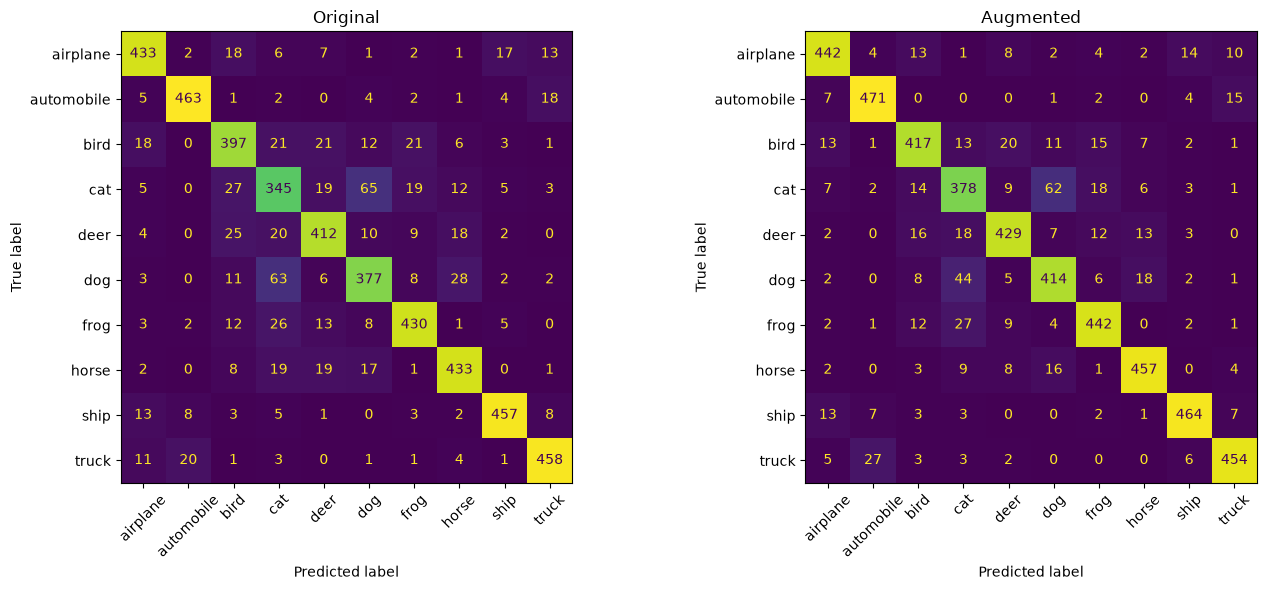

,model,accuracy,loss,macro_f1
0,Original,0.8410,0.8862,0.8412
1,Augmented,0.8736,0.3756,0.8736


In [36]:
@torch.inference_mode()
def collect_predictions(model, normalization_stats, loader):
    model.eval()
    # one row per validation image, so we can pick example images later
    rows = []
    for raw, targets, image_ids in loader:
        logits = model(prepare_inputs(raw.to(device), normalization_stats))
        confidence, prediction = logits.softmax(1).max(1)
        losses = nn.functional.cross_entropy(logits, targets.to(device), reduction="none")
        rows.append(pd.DataFrame({
            "image_id": image_ids.numpy(),
            "target": targets.numpy(),
            "prediction": prediction.cpu().numpy(),
            "confidence": confidence.cpu().numpy(),
            "loss": losses.cpu().numpy(),
        }))
    result = pd.concat(rows, ignore_index=True)
    result["correct"] = result.target == result.prediction
    return result

clean_predictions = {}
metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, (model, model_stats)) in zip(axes, analysis_models.items()):
    predictions = collect_predictions(model, model_stats, analysis_loader)
    clean_predictions[name] = predictions
    predictions.to_csv(analysis_dir / f"{name}_predictions.csv", index=False)
    report = classification_report(
        predictions.target,
        predictions.prediction,
        target_names=class_names,
        output_dict=True,
    )
    print(name)
    display(pd.DataFrame(report).T.round(3))
    metric_rows.append({
        "model": name,
        "accuracy": predictions.correct.mean(),
        "loss": predictions.loss.mean(),
        "macro_f1": report["macro avg"]["f1-score"],
    })
    ConfusionMatrixDisplay.from_predictions(
        predictions.target,
        predictions.prediction,
        display_labels=class_names,
        ax=ax,
        xticks_rotation=45,
        colorbar=False,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()
clean_metrics = pd.DataFrame(metric_rows)
display(clean_metrics.round(4))
clean_metrics.to_csv(analysis_dir / "clean_metrics.csv", index=False)

For each model, we look at the four classes with the lowest recall. For each class, the top row shows the first correct prediction and the bottom row shows the first wrong one, in validation order. Picking the images this way makes the selection repeatable. These eight images are only examples and do not cover every error.

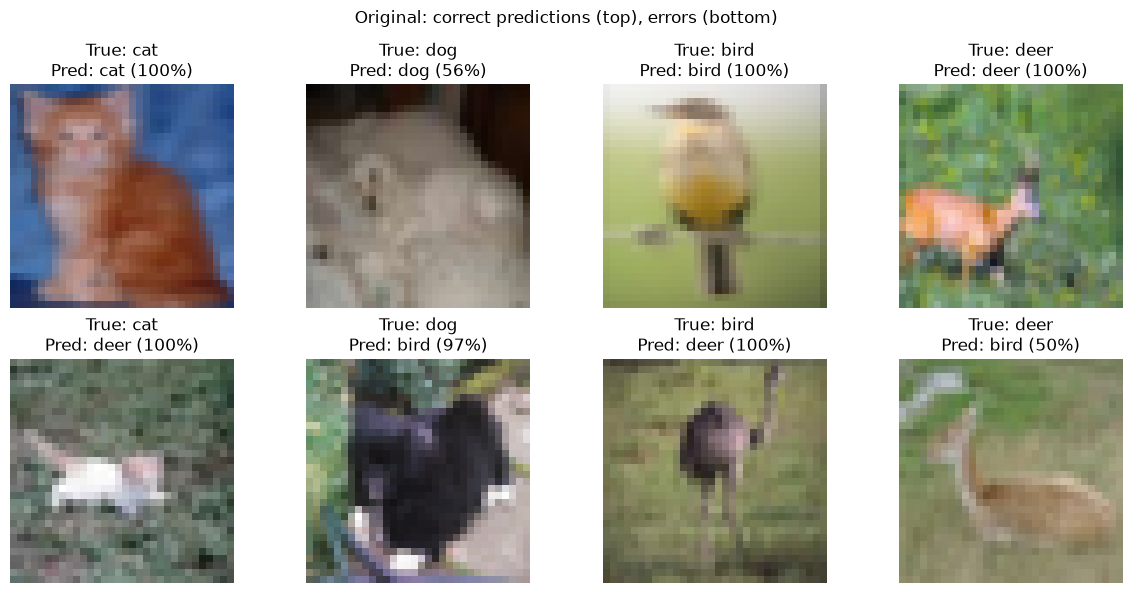

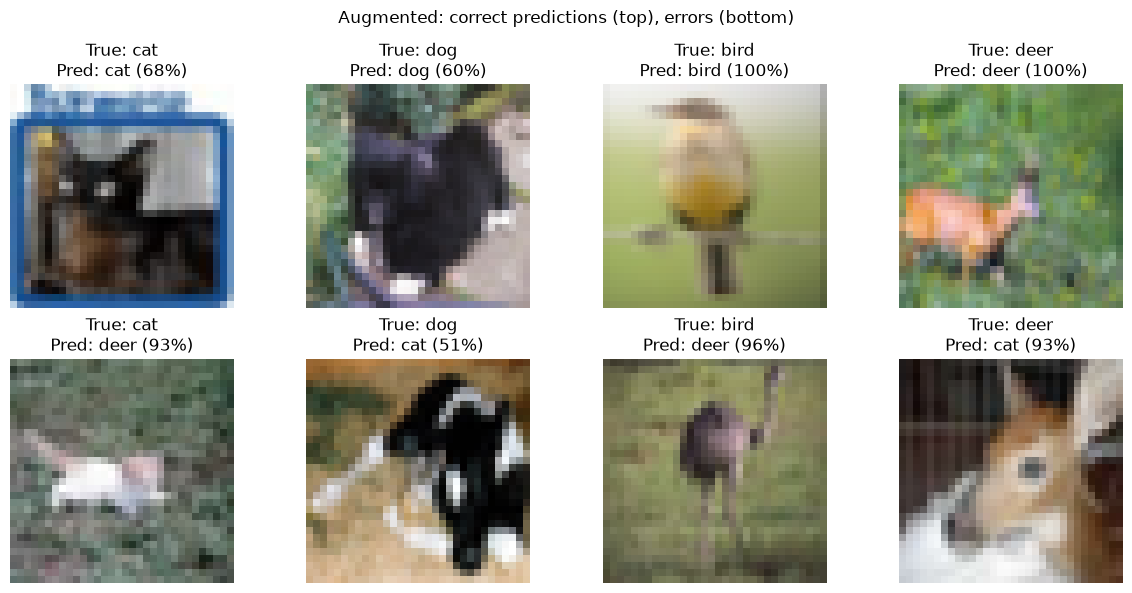

In [37]:
for name, predictions in clean_predictions.items():
    recall = predictions.groupby("target").correct.mean().sort_values()
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for col, target in enumerate(recall.index[:4]):
        for row, correct in enumerate([True, False]):
            example = predictions[
                (predictions.target == target) & (predictions.correct == correct)
            ].iloc[0]
            ax = axes[row, col]
            ax.imshow(database.data[int(example.image_id)])
            predicted = class_names[int(example.prediction)]
            ax.set_title(
                f"True: {class_names[target]}\nPred: {predicted} ({example.confidence:.0%})"
            )
            ax.axis("off")
    fig.suptitle(f"{name}: correct predictions (top), errors (bottom)")
    plt.tight_layout()
    plt.show()

We check the selected checkpoints in two ways. The table evaluates each checkpoint on clean training and validation images in evaluation mode. Dropout is off, so both sets are measured under the same conditions.

The learning curves come from the training logs. Their training metrics were recorded during training, while the weights were still changing and dropout was on. For Augmented, they were also computed on randomly cropped and flipped images. The validation metrics in the curves use evaluation mode and clean images. Because of this, the training numbers in the table and in the curves are not measured under the same conditions.

In [38]:
# clean training images (no crop/flip), so train and validation use the same conditions
clean_train_loader = DataLoader(
    RawImages(database, analysis_train_ids), batch_size=64, shuffle=False,
)
diagnostic_rows = []
for name, (model, model_stats) in analysis_models.items():
    training = evaluate(model, clean_train_loader, model_stats)
    validation = clean_metrics.set_index("model").loc[name]
    diagnostic_rows.append({
        "model": name,
        "best_epoch": checkpoint_info.loc[name, "best_epoch"],
        "train_loss": training.loss,
        "val_loss": validation.loss,
        "train_accuracy": training.accuracy,
        "val_accuracy": validation.accuracy,
        "gap_pp": 100 * (training.accuracy - validation.accuracy),
    })
diagnostics = pd.DataFrame(diagnostic_rows).set_index("model")
display(diagnostics.round(4))
diagnostics.to_csv(analysis_dir / "checkpoint_diagnostics.csv")

,best_epoch,train_loss,val_loss,train_accuracy,val_accuracy,gap_pp
model,,,,,,
Original,20,0.0019,0.8862,0.9998,0.8410,15.8844
Augmented,20,0.2093,0.3756,0.9288,0.8736,5.5244


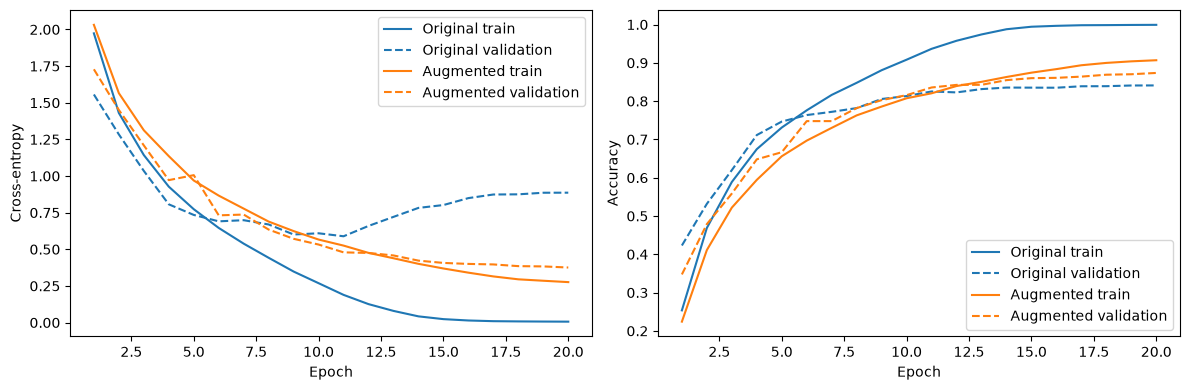

In [39]:
history_paths = {
    "Original": task2_output_dir / "AlexNet_history.csv",
    "Augmented": task4_output_dir / "AlexNet_augmented_history.csv",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (name, history_path), color in zip(history_paths.items(), ["tab:blue", "tab:orange"]):
    history = pd.read_csv(history_path)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(
            history.epoch, history[f"train_{metric}"],
            color=color, linestyle="-", label=f"{name} train",
        )
        ax.plot(
            history.epoch, history[f"val_{metric}"],
            color=color, linestyle="--", label=f"{name} validation",
        )
for ax, ylabel in zip(axes, ["Cross-entropy", "Accuracy"]):
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

### ResNet-18: predictions and training diagnostics

In order to analyze the predictions for the other model(the ResNet-18) we reuse the checkpoint selected in Task 2, without retraining. We evaluate it on the same clean validation images used for Original and Augmented AlexNet.

As above, we report per-class metrics and a confusion matrix, inspect correct and incorrect predictions from the four lowest-recall classes,
and compare training and validation performance. The Task 2 learning curves show how its performance developed during training.

In [16]:
# Load the checkpoints and add clean metrics
# Reuse the best ResNet-18 checkpoint from Task 2.
resnet_saved = torch.load(
    task2_output_dir / "ResNet18_best.pt",
    map_location="cpu",
    weights_only=True,
)
resnet_config = Run(**resnet_saved["config"])
resnet_model = build_model(resnet_config).to(device)
resnet_model.load_state_dict(resnet_saved["state_dict"])
resnet_model.eval()
resnet_stats = resnet_saved["stats"]

resnet_predictions = collect_predictions(
    resnet_model, resnet_stats, analysis_loader,
)
resnet_predictions.to_csv(
    analysis_dir / "ResNet18_predictions.csv", index=False,
)

resnet_report = classification_report(
    resnet_predictions.target,
    resnet_predictions.prediction,
    labels=range(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
print("ResNet18")
display(pd.DataFrame(resnet_report).T.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    resnet_predictions.target,
    resnet_predictions.prediction,
    labels=range(len(class_names)),
    display_labels=class_names,
    ax=ax,
    xticks_rotation=45,
    colorbar=False,
)
ax.set_title("ResNet18")
plt.tight_layout()
plt.show()

resnet_metrics = pd.DataFrame([{
    "model": "ResNet18",
    "accuracy": resnet_predictions.correct.mean(),
    "loss": resnet_predictions.loss.mean(),
    "macro_f1": resnet_report["macro avg"]["f1-score"],
}])

# Compare with the two AlexNet conditions evaluated above.
clean_comparison = pd.concat(
    [clean_metrics, resnet_metrics], ignore_index=True,
)
display(clean_comparison.round(4))
clean_comparison.to_csv(
    analysis_dir / "clean_comparison_with_resnet.csv", index=False,
)

NameError: name 'task2_output_dir' is not defined

In [ ]:
# Same selection rule as for the other models: the four lowest-recall classes.
resnet_recall = (
    resnet_predictions.groupby("target").correct.mean().sort_values()
)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, target in enumerate(resnet_recall.index[:4]):
    for row, correct in enumerate([True, False]):
        ax = axes[row, col]
        examples = resnet_predictions[
            (resnet_predictions.target == target)
            & (resnet_predictions.correct == correct)
        ]
        if examples.empty:
            ax.set_title(f"True: {class_names[target]}\nNo example")
            ax.axis("off")
            continue

        example = examples.iloc[0]
        ax.imshow(database.data[int(example.image_id)])
        predicted = class_names[int(example.prediction)]
        ax.set_title(
            f"True: {class_names[target]}\n"
            f"Pred: {predicted} ({example.confidence:.0%})"
        )
        ax.axis("off")

fig.suptitle("ResNet18: correct predictions (top), errors (bottom)")
plt.tight_layout()
plt.show()

In [ ]:
# Clean training images, using the saved weights in evaluation mode.
resnet_training = evaluate(
    resnet_model, clean_train_loader, resnet_stats,
)
resnet_validation = resnet_metrics.iloc[0]

resnet_diagnostics = pd.DataFrame([{
    "model": "ResNet18",
    "best_epoch": resnet_saved["epoch"],
    "train_loss": resnet_training.loss,
    "val_loss": resnet_validation["loss"],
    "train_accuracy": resnet_training.accuracy,
    "val_accuracy": resnet_validation["accuracy"],
    "gap_pp": 100 * (
        resnet_training.accuracy - resnet_validation["accuracy"]
    ),
}]).set_index("model")

diagnostic_comparison = pd.concat([diagnostics, resnet_diagnostics])
display(diagnostic_comparison.round(4))
diagnostic_comparison.to_csv(
    analysis_dir / "checkpoint_diagnostics_with_resnet.csv",
)

hardest_class = int(resnet_recall.index[0])
print(
    f"Lowest-recall class: {class_names[hardest_class]} "
    f"({resnet_recall.iloc[0]:.2%})"
)
print(
    "ResNet18 validation accuracy minus Original AlexNet: "
    f"{100 * (resnet_validation['accuracy'] - clean_metrics.set_index('model').loc['Original', 'accuracy']):+.2f} pp"
)

# Release this copy; Task 6 loads ResNet again for inference timing.
del resnet_model

FGSM takes one step in the direction of the sign of the gradient of the cross-entropy loss with respect to the raw pixels. As in classroom A8, we fix `epsilon = 4/255` before running the attack. Each pixel can change by at most epsilon, and the result is clipped to [0, 1]. The normalization step stays inside the gradient computation.

We attack the first 256 validation images, and each model is attacked with its own gradients. We count an attack as successful when a correct clean prediction becomes wrong. This means the success rate only uses images that the model first classified correctly.

As a control, we also add random signs with the same epsilon and clipping. Both models get the same random perturbations, and these do not use any gradient.

In [40]:
# FGSM as in A8: gradient w.r.t. the raw pixels, with normalization inside the graph
def fgsm(model, raw, targets, normalization_stats, epsilon):
    model.eval()
    attack_input = raw.detach().clone().requires_grad_(True)
    logits = model(prepare_inputs(attack_input, normalization_stats))
    loss = nn.functional.cross_entropy(logits, targets)
    (gradient,) = torch.autograd.grad(loss, attack_input)
    return (attack_input + epsilon * gradient.sign()).clamp(0, 1).detach()

epsilon = 4 / 255
attack_loader = DataLoader(
    RawImages(database, analysis_ids[:256]), batch_size=64, shuffle=False,
)
attack_rows = []
attack_examples = {}
attack_max_linf = {}
for name, (model, model_stats) in analysis_models.items():
    # reset the generator for each model, so both models get the same random signs
    generator = torch.Generator().manual_seed(2223)
    attack_max_linf[name] = 0.0
    for raw, targets, image_ids in attack_loader:
        signs = 2 * torch.randint(0, 2, raw.shape, generator=generator) - 1
        random_input = (raw + epsilon * signs).clamp(0, 1).to(device)
        raw, targets = raw.to(device), targets.to(device)
        adversarial = fgsm(model, raw, targets, model_stats, epsilon)
        attack_max_linf[name] = max(
            attack_max_linf[name], (adversarial - raw).abs().max().item(),
        )
        with torch.inference_mode():
            clean = model(prepare_inputs(raw, model_stats)).argmax(1)
            random_pred = model(prepare_inputs(random_input, model_stats)).argmax(1)
            attack_pred = model(prepare_inputs(adversarial, model_stats)).argmax(1)
        # success: correct before the attack and wrong after it
        success = (clean == targets) & (attack_pred != targets)
        attack_rows.append(pd.DataFrame({
            "model": name,
            "image_id": image_ids.numpy(),
            "target": targets.cpu().numpy(),
            "clean_prediction": clean.cpu().numpy(),
            "random_prediction": random_pred.cpu().numpy(),
            "fgsm_prediction": attack_pred.cpu().numpy(),
        }))
        if name not in attack_examples and success.any():
            i = int(success.nonzero()[0])
            attack_examples[name] = (
                raw[i].cpu(),
                random_input[i].cpu(),
                adversarial[i].cpu(),
                int(targets[i]),
                int(clean[i]),
                int(random_pred[i]),
                int(attack_pred[i]),
            )

attack_details = pd.concat(attack_rows, ignore_index=True)
attack_details.to_csv(analysis_dir / "attack_predictions.csv", index=False)

Next, we summarize clean accuracy, accuracy with random signs and FGSM success on the 256 images.

In [41]:
attack_summary_rows = []
for name, rows in attack_details.groupby("model", sort=False):
    initially_correct = rows.clean_prediction == rows.target
    attack_summary_rows.append({
        "model": name,
        "images": len(rows),
        "initially_correct": int(initially_correct.sum()),
        "clean_accuracy": initially_correct.mean(),
        "random_accuracy": (rows.random_prediction == rows.target).mean(),
        "fgsm_accuracy": (rows.fgsm_prediction == rows.target).mean(),
        "attack_success_rate": (
            rows.loc[initially_correct, "fgsm_prediction"]
            != rows.loc[initially_correct, "target"]
        ).mean(),
        "max_linf": attack_max_linf[name],
    })
attack_summary = pd.DataFrame(attack_summary_rows)
display(attack_summary.round(4))
attack_summary.to_csv(analysis_dir / "attack_summary.csv", index=False)

,model,images,initially_correct,clean_accuracy,random_accuracy,fgsm_accuracy,attack_success_rate,max_linf
0,Original,256,219,0.8555,0.8633,0.2656,0.6895,0.0157
1,Augmented,256,235,0.9180,0.9102,0.2578,0.7191,0.0157


Below is the first successful adversarial example for each model. The last panel shows the perturbation, amplified so that it is visible.

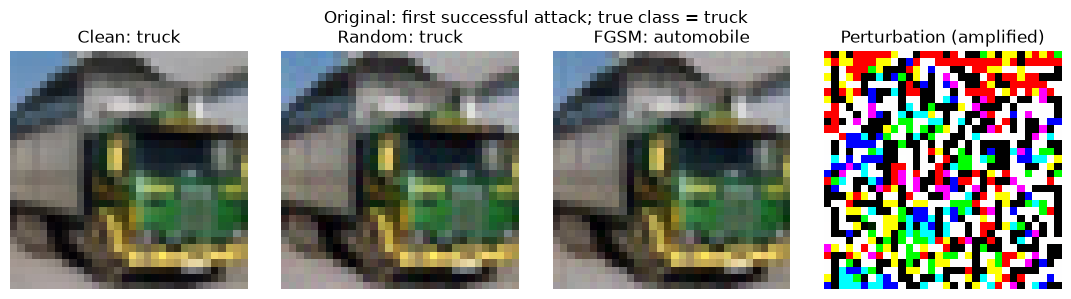

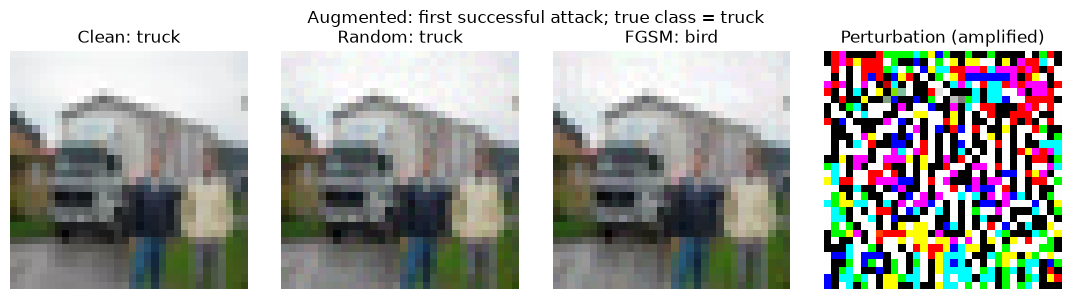

In [42]:
for name, example in attack_examples.items():
    raw, random_input, adversarial, target, clean, random_pred, attack_pred = example
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    images = [raw, random_input, adversarial, 0.5 + (adversarial - raw) / (2 * epsilon)]
    titles = [f"Clean: {class_names[clean]}", f"Random: {class_names[random_pred]}",
              f"FGSM: {class_names[attack_pred]}", "Perturbation (amplified)"]
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"{name}: first successful attack; true class = {class_names[target]}")
    plt.tight_layout()
    plt.show()

**Predictions and training diagnostics**

Original reached 84.10% clean accuracy and Augmented reached 87.36%. Their validation losses were 0.886 and 0.376. The least-recalled class for Original was cat (69.00%). For example, it classified image 39 as deer with almost 100% confidence.

On clean inputs, the gap between training and validation accuracy was 15.88 points for Original and 5.52 for Augmented. Training accuracy in this check uses the saved weights with dropout off. The learning curves use training-mode accuracy during optimization.

Original had its lowest validation loss at epoch 11 and ended at 0.886. For Augmented the validation loss went from 0.407 at epoch 15 to 0.376 at epoch 20.

**Adversarial examples**

FGSM used each model's own gradient on the first 256 validation images. We added 4/255 times the sign of the gradient to each pixel and clipped to [0,1]. The largest change was 0.0156863. Random signs of the same size caused far fewer errors. The success rate counts only images classified correctly before the attack.

| Model | Clean | Random | FGSM | Successful attacks |
| --- | --- | --- | --- | --- |
| Original | 85.55% | 86.33% | 26.56% | 151/219 (68.95%) |
| Augmented | 91.80% | 91.02% | 25.78% | 169/235 (71.91%) |

On initially correct predictions the attack succeeded more often against Augmented (71.91%) than Original (68.95%). Crop-and-flip training improved clean validation accuracy, but gave no FGSM advantage on this subset. The first 256 validation images are a small, unstratified sample.

## Task 6. Benchmark and Discuss the Tradeoffs
Measure the costs that matter for your intended use and relate them to accuracy, robustness and the compute budget. Choose and describe an inference timing, device, precision and batch size. Discuss how training duration, randomness and hardware constrain the conclusions, and recommend a model or configuration using your measured evidence.

We time all three models on the same device with batches of 1 and 64. Each trial uses five warm-up passes followed by 20 timed passes. We alternate the order across six trials and report the median and the 25th and 75th percentiles. Inputs are float32 with cuDNN TF32 allowed. Timing excludes loading, preprocessing and transfers. Training times come from this run.

In [43]:
# same timing loop as A8: warm up, synchronize, then average 20 forward passes
@torch.inference_mode()
def time_inference(model, inputs):
    model.eval()
    for _ in range(5):
        model(inputs)
    synchronize_device()
    start = time.perf_counter()
    for _ in range(20):
        model(inputs)
    synchronize_device()
    return 1000 * (time.perf_counter() - start) / 20

resnet = build_model(resnet_run).to(device)
resnet_saved = torch.load(task2_output_dir / "ResNet18_best.pt", map_location="cpu", weights_only=True)
resnet.load_state_dict(resnet_saved["state_dict"])
timing_models = {**analysis_models, "ResNet18": (resnet.eval(), resnet_saved["stats"])}
timing_rows = []
raw_batch = next(iter(analysis_loader))[0].to(device)
for batch_size in [1, 64]:
    prepared = {
        name: prepare_inputs(raw_batch[:batch_size], model_stats)
        for name, (_, model_stats) in timing_models.items()
    }
    for trial in range(6):
        # Alternate which model runs first to reduce measurement-order effects.
        names = list(timing_models)
        if trial % 2:
            names.reverse()
        for name in names:
            model = timing_models[name][0]
            batch_ms = time_inference(model, prepared[name])
            timing_rows.append({
                "model": name,
                "batch_size": batch_size,
                "trial": trial + 1,
                "batch_ms": batch_ms,
            })
timing_trials = pd.DataFrame(timing_rows)
timing_trials.to_csv(analysis_dir / "timing_trials.csv", index=False)
timings = (
    timing_trials.groupby(["model", "batch_size"]).batch_ms
    .agg(
        median_ms="median",
        q25_ms=lambda x: x.quantile(.25),
        q75_ms=lambda x: x.quantile(.75),
    )
    .reset_index()
)
timings["ms_per_image"] = timings.median_ms / timings.batch_size
timings["images_per_second"] = 1000 * timings.batch_size / timings.median_ms
display(timings.round(3))
timings.to_csv(analysis_dir / "inference_timing.csv", index=False)
environment = {
    "device": str(device),
    "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else str(device),
    "torch": str(torch.__version__),
    "cudnn_tf32": torch.backends.cudnn.allow_tf32,
    "cuda_matmul_tf32": torch.backends.cuda.matmul.allow_tf32,
}
(analysis_dir / "environment.json").write_text(json.dumps(environment, indent=2))
print(environment)

,model,batch_size,median_ms,q25_ms,q75_ms,ms_per_image,images_per_second
0,Augmented,1,0.976,0.969,1.002,0.976,1024.853
1,Augmented,64,4.924,4.916,4.940,0.077,12997.834
2,Original,1,1.004,0.979,1.044,1.004,995.815
3,Original,64,4.939,4.913,4.948,0.077,12956.967
4,ResNet18,1,3.600,3.365,3.904,3.600,277.788
5,ResNet18,64,17.232,17.215,17.265,0.269,3713.983


{'device': 'cuda', 'device_name': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU', 'torch': '2.7.1+cu128', 'cudnn_tf32': True, 'cuda_matmul_tf32': False}


In [44]:
display(accuracy_table.round(2))

costs = checkpoint_info[["parameters", "epochs", "trained_samples"]].join(
    clean_metrics.set_index("model")
)
costs["checkpoint_mib"] = [
    checkpoint_paths[name].stat().st_size / 1024**2 for name in costs.index
]
display(costs.round(4))
costs.to_csv(analysis_dir / "model_comparison.csv")

# training times come from the logs written by train_model in Tasks 2 and 4
training_cost = pd.concat([
    pd.read_csv(task2_output_dir / "comparison.csv"),
    pd.read_csv(task4_output_dir / "training_comparison.csv"),
]).set_index("name").loc[["AlexNet", "AlexNet_augmented", "ResNet18"]]
training_cost.index = pd.Index(
    ["AlexNet (Original)", "AlexNet (Augmented)", "ResNet18"], name="model",
)
training_cost["wall_minutes"] = training_cost.wall_seconds / 60
training_cost = training_cost[["parameters", "best_epoch", "best_val_accuracy", "wall_minutes"]]
display(training_cost.round(4))
training_cost.to_csv(analysis_dir / "training_cost.csv")

model,Augmented,Original,augmentation_gain_pp
condition,,,
clean,87.36,84.10,3.26
noise_0.05,76.74,78.32,-1.58
noise_0.10,44.24,56.22,-11.98
rotation_10,73.50,66.54,6.96
rotation_25,51.22,44.06,7.16
blur_0.5,84.04,80.72,3.32
blur_1.0,51.02,53.86,-2.84


,parameters,epochs,trained_samples,accuracy,loss,macro_f1,checkpoint_mib
model,,,,,,,
Original,6976842,20,900000,0.8410,0.8862,0.8412,26.6206
Augmented,6976842,20,900000,0.8736,0.3756,0.8736,26.6209


,parameters,best_epoch,best_val_accuracy,wall_minutes
model,,,,
AlexNet (Original),6976842,20,0.8410,6.4355
AlexNet (Augmented),6976842,20,0.8736,8.2269
ResNet18,11173962,19,0.8508,17.5160


**Model choice and cost**

For mostly clean or rotated images, we would use Augmented. It gained 3.26 validation points on clean images and 7.16 points at 25 degrees of rotation for 28% more training time. At batch size 64, its median inference time was 4.92 ms, close to Original at 4.94 ms. Augmented also gained 3.32 points under mild blur. Original was the better choice for strong noise and strong blur, where Augmented lost 11.98 and 2.84 points. Augmented showed no advantage on our FGSM subset.

ResNet-18 gained 0.98 clean validation points over Original for 2.72 times the training time and 3.49 times the batch-64 inference time. We only tested corruptions and FGSM on the two AlexNet checkpoints. In the width comparison, the wider AlexNet gained 0.72 points for 1.58 times the training time.

Augmented's validation loss was still falling at epoch 20, so a longer budget could change the ranking. We used one seed on one laptop GPU. The two baseline runs reached the same validation accuracy, but their training times differed by about 4%. Training ResNet-18 with crop and flip would let us compare architectures under the same augmentation.

The following cells show the final checkpoint selection and the official test result.


### Final evaluation on the official test set

Among the configurations trained for 20 epochs, we choose the checkpoint with the highest validation accuracy. Lower validation loss breaks a tie. We then evaluate this one checkpoint on the 10,000 official test images.

In [45]:
candidates = pd.concat([comparison, comparison_task3, pd.DataFrame([asdict(augmented_summary)])])
selected = candidates.sort_values(["best_val_accuracy", "best_val_loss"], ascending=[False, True]).iloc[0]
saved = torch.load(selected.checkpoint, map_location="cpu", weights_only=True)
final_run = Run(**saved["config"])
final_model = build_model(final_run).to(device)
final_model.load_state_dict(saved["state_dict"])
test_loader = make_loaders(final_run, train_ids, val_ids, include_test=True).test
test_metrics = evaluate(final_model, test_loader, saved["stats"])
test_result = pd.DataFrame([dict(model=final_run.name, checkpoint=selected.checkpoint,
                                epoch=saved["epoch"], val_accuracy=saved["val_accuracy"],
                                test_samples=test_metrics.samples, test_loss=test_metrics.loss,
                                test_accuracy=test_metrics.accuracy)])
test_result.to_csv(analysis_dir / "official_test.csv", index=False)
display(test_result)

,model,checkpoint,epoch,val_accuracy,test_samples,test_loss,test_accuracy
0,AlexNet_augmented,outputs\task4\20261124T214229Z_5c04b362\AlexNe...,20,0.8736,10000,0.399194,0.8713


## Challenge 1. Model Compression
Investigate whether a trained model can be represented by a smaller or faster model without an unacceptable loss in performance. Choose a method, define what efficiency and acceptable accuracy change mean for your use case, and compare the result with an appropriate reference under a consistent protocol. Report compression or fine-tuning cost as well as deployment cost. A smaller parameter count, sparse mask or smaller file does not automatically imply faster inference.

Not attempted.

## Challenge 2. Generalization Beyond the Development Conditions
Investigate whether your model generalizes to an unseen corruption family or a different, suitably labelled image domain. Choose a meaningful shift, explain its relationship to development data, and decide how to measure success. Discuss your findings.

Not attempted.

## References
- [ID2223 Lab Session 2, A7-A9: model diagnostics, FGSM, timing and CIFAR-10 architectures](lab-session-notebook.ipynb)
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)
- [AlexNet original paper](https://papers.nips.cc/paper/4824-imagenet-classification-with-deep-convolutional-neural-networks)
- [ResNet original paper](https://arxiv.org/abs/1512.03385)
- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [LocalResponseNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.LocalResponseNorm.html)
- [FGSM background](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html)